In [1]:
import pandas as pd
df=pd.read_excel('/content/SALEs.xlsx')
df.head()

,INV_HEAD_TYPE,CUST_CODE,A.CUST_CODE||A.CUST_DEPT_CODE||A.CUST_CITY_CODE,CITY_NAME,PIN,DISTINATION,IDENTIFIER,DATES,PROD_CODE,NO. OF LICENSES,RATE,BASIC,EXCISE_DUTY,CESS,ADL_CESS,GST,AMOUNT,GL_CD_GROSS
0,B,E0020,E0020HOFARD,FARIDABAD,121003,FARIDABAD,21-22/CP/1275,2022-12-01 00:00:00,SF-EXA-1340,568,43.91,24940.88,0,0,0,0,24940.88,NaN
1,B,E0020,E0020HOFARD,FARIDABAD,121003,FARIDABAD,21-22/CP/0450,8/27/2021,SF-EXA-1340,227,43.91,9967.57,0,0,0,0,9967.57,NaN
2,B,E0020,E0020HOFARD,FARIDABAD,121003,FARIDABAD,21-22/CP/0236,7/20/2021,SF-EXA-1340,630,43.91,27663.3,0,0,0,0,27663.3,NaN
3,B,E0020,E0020HOFARD,FARIDABAD,121003,FARIDABAD,21-22/CP/0221,7/17/2021,SF-EXA-1340,450,43.91,19759.5,0,0,0,0,19759.5,NaN
4,B,E0020,E0020HOFARD,FARIDABAD,121003,FARIDABAD,21-22/CP/0224,7/17/2021,SF-EXA-1340,270,43.91,11855.7,0,0,0,0,11855.7,NaN


In [ ]:
df.shape

In [2]:
df.columns

Index(['INV_HEAD_TYPE', 'CUST_CODE',
       'A.CUST_CODE||A.CUST_DEPT_CODE||A.CUST_CITY_CODE', 'CITY_NAME', 'PIN',
       'DISTINATION', 'IDENTIFIER', 'DATES', 'PROD_CODE', 'NO. OF LICENSES',
       'RATE', 'BASIC', 'EXCISE_DUTY', 'CESS', 'ADL_CESS', 'GST', 'AMOUNT',
       'GL_CD_GROSS'],
      dtype='object')

In [3]:
df.drop(columns=['INV_HEAD_TYPE','A.CUST_CODE||A.CUST_DEPT_CODE||A.CUST_CITY_CODE', 'DISTINATION', 'IDENTIFIER', 'BASIC', 'CESS', 'ADL_CESS', 'GL_CD_GROSS'], inplace=True)

In [4]:
df= df.rename(columns={
    'CUST_CODE':'Client_ID',
    'DATES': 'Invoice Date',
    'PROD_CODE': 'Service Code',
    'QUANTITY': 'No. of Licenses',
    'RATE': 'Service_Rate',
    'AMOUNT': 'Value',
    'EXCISE_DUTY':'Excess_duty',
    'CITY_NAME': 'Client City',
    'NO. OF LICENSES': 'No. of Licenses'
})

In [5]:
df.head()

,Client_ID,Client City,PIN,Invoice Date,Service Code,No. of Licenses,Service_Rate,Excess_duty,GST,Value
0,E0020,FARIDABAD,121003,2022-12-01 00:00:00,SF-EXA-1340,568,43.91,0,0,24940.88
1,E0020,FARIDABAD,121003,8/27/2021,SF-EXA-1340,227,43.91,0,0,9967.57
2,E0020,FARIDABAD,121003,7/20/2021,SF-EXA-1340,630,43.91,0,0,27663.3
3,E0020,FARIDABAD,121003,7/17/2021,SF-EXA-1340,450,43.91,0,0,19759.5
4,E0020,FARIDABAD,121003,7/17/2021,SF-EXA-1340,270,43.91,0,0,11855.7


In [6]:
df.isnull().sum()

,0
Client_ID,0
Client City,770
PIN,5108
Invoice Date,49
Service Code,81
No. of Licenses,3224
Service_Rate,107
Excess_duty,540763
GST,637894
Value,103451


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 770264 entries, 0 to 770263
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Client_ID        770264 non-null  object
 1   Client City      769494 non-null  object
 2   PIN              765156 non-null  object
 3   Invoice Date     770215 non-null  object
 4   Service Code     770183 non-null  object
 5   No. of Licenses  767040 non-null  object
 6   Service_Rate     770157 non-null  object
 7   Excess_duty      229501 non-null  object
 8   GST              132370 non-null  object
 9   Value            666813 non-null  object
dtypes: object(10)
memory usage: 58.8+ MB


# Fix data types

In [8]:
df['Invoice Date'] = pd.to_datetime(
    df['Invoice Date'],
    errors='coerce'
)

In [9]:
numeric_cols = [
    'No. of Licenses',
    'PIN',
    'Service_Rate',
    'Value',
    'Excess_duty',
    'GST'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

# Feature Engineering

In [10]:
df['Total_Bill'] = df['Value'] + df['GST'] + df['Excess_duty']

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 770264 entries, 0 to 770263
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Client_ID        770264 non-null  object        
 1   Client City      769494 non-null  object        
 2   PIN              763996 non-null  float64       
 3   Invoice Date     764807 non-null  datetime64[ns]
 4   Service Code     770183 non-null  object        
 5   No. of Licenses  637042 non-null  float64       
 6   Service_Rate     700742 non-null  float64       
 7   Excess_duty      205700 non-null  float64       
 8   GST              118067 non-null  float64       
 9   Value            652511 non-null  float64       
 10  Total_Bill       108569 non-null  float64       
dtypes: datetime64[ns](1), float64(7), object(3)
memory usage: 64.6+ MB


In [12]:
df = df.dropna(subset=['Client City'])
df = df.dropna(subset=['Service Code'])
df = df.dropna(subset=['Invoice Date'])

df['PIN'] = df['PIN'].astype('Int64')
df['PIN'] = df['PIN'].fillna(-1)

In [13]:
df.describe()

,PIN,Invoice Date,No. of Licenses,Service_Rate,Excess_duty,GST,Value,Total_Bill
count,764388.0,764388,637042.000000,6.959260e+05,1.999720e+05,113513.000000,6.479700e+05,1.040340e+05
mean,416645.641499,2023-08-07 05:17:17.121964288,497.932835,2.894392e+02,4.725855e+03,362.982836,1.721225e+04,6.012472e+04
min,-1.0,1970-01-01 00:00:00.000000031,0.000000,0.000000e+00,0.000000e+00,0.000000,-1.000000e-02,4.600000e-01
25%,221002.0,2022-05-03 00:00:00,20.000000,6.278000e+01,0.000000e+00,0.000000,3.358060e+03,5.765040e+03
50%,440002.0,2023-05-24 00:00:00,48.000000,1.071000e+02,1.600000e+01,0.000000,5.175080e+03,1.606450e+04
75%,575002.0,2024-11-30 00:00:00,100.000000,1.797750e+02,3.170614e+03,0.000000,9.828055e+03,4.929216e+04
max,855108.0,2026-12-03 00:00:00,390000.000000,5.905745e+06,2.779947e+06,938000.000000,7.425251e+06,6.567160e+06
std,203514.09658,NaN,4081.727623,1.498112e+04,2.601162e+04,4095.079734,8.477007e+04,1.598547e+05


In [14]:
df['Excess_duty'] = (
    df['Excess_duty']
    .fillna(0)
)

In [15]:
df['GST'] = df['GST'].fillna(0)

In [16]:
df['Service Code'] = (
    df['Service Code']
    .astype(str)
    .str.strip()
)

In [17]:
df.isnull().sum()

,0
Client_ID,0
Client City,0
PIN,0
Invoice Date,0
Service Code,0
No. of Licenses,127346
Service_Rate,68462
Excess_duty,0
GST,0
Value,116418


# Validate Business Logic
1. Value = Quantity × Rate

In [18]:
sample = df[
    (df['No. of Licenses'].notna()) &
    (df['Service_Rate'].notna()) &
    (df['Value'].notna())
]

sample['Calc_Value'] = (
    sample['No. of Licenses'] *
    sample['Service_Rate']
)

sample[['Value','Calc_Value']].head(20)

/tmp/ipykernel_2545/4094769312.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample['Calc_Value'] = (


,Value,Calc_Value
0,24940.88,24940.88
1,9967.57,9967.57
2,27663.30,27663.30
3,19759.50,19759.50
4,11855.70,11855.70
5,77890.82,77890.82
6,43377.25,43377.25
7,17527.95,17527.95
8,92951.25,92951.25
9,74361.00,74361.00


In [19]:
# Recover service_rate
mask = (
    df['Service_Rate'].isna()
    & df['Value'].notna()
    & (df['No. of Licenses'] > 0)
)

print(mask)

df.loc[mask, 'Service_Rate'] = (
    df.loc[mask, 'Value']
    /
    df.loc[mask, 'No. of Licenses']
)

0         False
1         False
2         False
3         False
4         False
          ...  
770259    False
770260    False
770261    False
770262    False
770263    False
Length: 764388, dtype: bool


In [20]:
# REcover No. of License
mask = (
    df['No. of Licenses'].isna()
    & df['Value'].notna()
    & (df['Service_Rate'] > 0)
)

df.loc[mask, 'No. of Licenses'] = (
    df.loc[mask, 'Value']
    /
    df.loc[mask, 'Service_Rate']
)

In [21]:
df.isnull().sum()

,0
Client_ID,0
Client City,0
PIN,0
Invoice Date,0
Service Code,0
No. of Licenses,121256
Service_Rate,67762
Excess_duty,0
GST,0
Value,116418


In [22]:
print(df['Service Code'].dtype)

object


In [23]:
df['Service Code'].apply(type).value_counts()

,count
Service Code,
<class 'str'>,764388


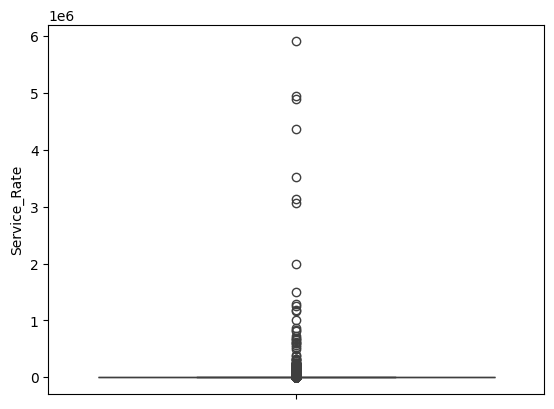

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(df['Service_Rate'])
plt.show()

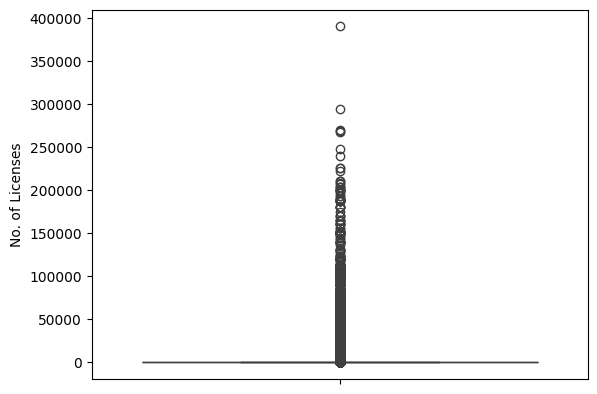

In [26]:
sns.boxplot(df['No. of Licenses'])
plt.show()

Outlier existence require median imputation in the missing values of these columns.

In [27]:
# Fill No. of Licenses and Service_Rate using Service wise median
service_rate_median = (
    df.groupby('Service Code')['Service_Rate']
      .median()
)

df['Service_Rate'] = df['Service_Rate'].fillna(
    df['Service Code'].map(service_rate_median)
)

In [28]:

license_median = (
    df.groupby('Service Code')['No. of Licenses']
      .median()
)

df['No. of Licenses'] = df['No. of Licenses'].fillna(
    df['Service Code'].map(license_median)
)

In [29]:
# Remaining nulls
df['Service_Rate'] = df['Service_Rate'].fillna(
    df['Service_Rate'].median()
)

df['No. of Licenses'] = df['No. of Licenses'].fillna(
    df['No. of Licenses'].median()
)

In [30]:
mask = df['Value'].isna()

df.loc[mask, 'Value'] = (
    df.loc[mask, 'No. of Licenses']
    *
    df.loc[mask, 'Service_Rate']
)

In [31]:
mask = df['Total_Bill'].isna()

df.loc[mask, 'Total_Bill'] = (
    df.loc[mask, 'Value']
    +
    df.loc[mask, 'GST']
    +
    df.loc[mask, 'Excess_duty']
)

In [32]:
df.isnull().sum()

,0
Client_ID,0
Client City,0
PIN,0
Invoice Date,0
Service Code,0
No. of Licenses,0
Service_Rate,0
Excess_duty,0
GST,0
Value,0


In [33]:
df.duplicated().sum()

np.int64(4193)

In [34]:
df.drop_duplicates(inplace=True)

In [35]:
df.shape

(760195, 11)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 760195 entries, 0 to 770263
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Client_ID        760195 non-null  object        
 1   Client City      760195 non-null  object        
 2   PIN              760195 non-null  Int64         
 3   Invoice Date     760195 non-null  datetime64[ns]
 4   Service Code     760195 non-null  object        
 5   No. of Licenses  760195 non-null  float64       
 6   Service_Rate     760195 non-null  float64       
 7   Excess_duty      760195 non-null  float64       
 8   GST              760195 non-null  float64       
 9   Value            760195 non-null  float64       
 10  Total_Bill       760195 non-null  float64       
dtypes: Int64(1), datetime64[ns](1), float64(6), object(3)
memory usage: 70.3+ MB


In [37]:
df.to_csv('FinalSales.csv')